# 03 - Decision Tree

Our implementation is in `src/decision_tree.py`. What we try:
1. **maximum depth**, with both splitting criteria (Gini and entropy)
2. **minimum samples per leaf** and **per split**
3. a small grid combining depth and leaf size
4. **n_bins**, the number of candidate thresholds per feature (a choice in our implementation)

For every setting we record **training and validation accuracy**. The gap between them tells us
whether the tree is under- or over-fitting. Trees don't need preprocessing (a threshold works
the same on any order-preserving rescaling), so we use the raw features.

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data import get_split, N_CLASSES
from src.decision_tree import DecisionTreeClassifier
from src.utils import COLORS, accuracy, Timer, save_table, save_figure, save_predictions, set_seed

set_seed()
splits = {task: get_split(task) for task in ("image", "sentiment")}

## 1. Maximum depth x criterion

Shortcut: a tree grows top-down, so a tree trained with `max_depth=d` is exactly the top d
levels of a fully grown tree. So we grow one full tree per criterion and read off every depth
with `predict(X, max_depth=d)`. The last line of the cell checks this once against a real retrain.

In [2]:
DEPTHS = [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20, 25, 30, 40, None]
rows, full_trees = [], {}
for task, (Xtr, ytr, Xva, yva) in splits.items():
    for criterion in ("gini", "entropy"):
        with Timer() as t:
            tree = DecisionTreeClassifier(criterion=criterion).fit(Xtr, ytr, N_CLASSES[task])
        full_trees[(task, criterion)] = tree
        print(f"{task:9s} {criterion:8s} full tree: depth {tree.depth}, {tree.n_leaves} leaves, {t.seconds:.1f}s")
        for d in DEPTHS:
            rows.append(dict(task=task, criterion=criterion, max_depth=d if d is not None else tree.depth,
                             train_acc=accuracy(ytr, tree.predict(Xtr, max_depth=d)),
                             val_acc=accuracy(yva, tree.predict(Xva, max_depth=d))))
depth_results = pd.DataFrame(rows).drop_duplicates(["task", "criterion", "max_depth"])
save_table(depth_results, "dt_depth_sweep")

Xtr, ytr, Xva, yva = splits["sentiment"]
retrained = DecisionTreeClassifier(max_depth=6).fit(Xtr, ytr)
print("shortcut gives the same predictions as retraining with max_depth=6:",
      np.array_equal(retrained.predict(Xva), full_trees[("sentiment", "gini")].predict(Xva, max_depth=6)))

image     gini     full tree: depth 92, 9453 leaves, 45.5s


image     entropy  full tree: depth 48, 9664 leaves, 49.5s


sentiment gini     full tree: depth 24, 1491 leaves, 6.5s


sentiment entropy  full tree: depth 17, 1309 leaves, 8.4s


shortcut gives the same predictions as retraining with max_depth=6: True


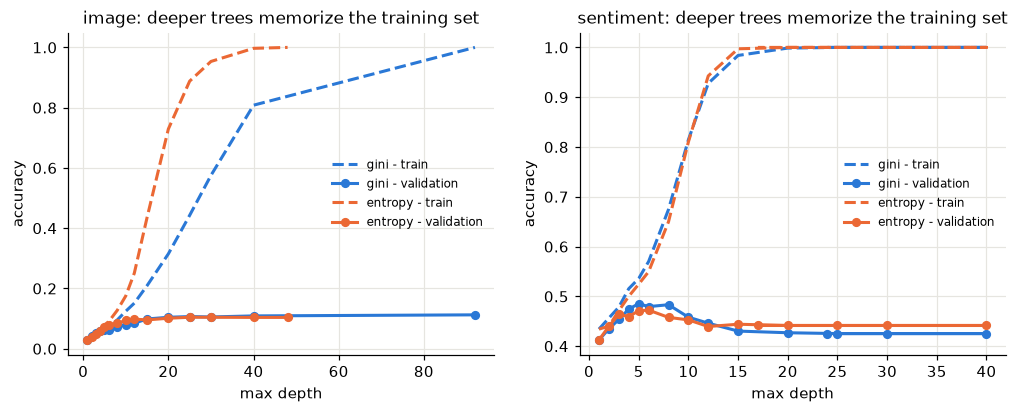

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, task in zip(axes, splits):
    for j, criterion in enumerate(("gini", "entropy")):
        r = depth_results[(depth_results.task == task) & (depth_results.criterion == criterion)]
        ax.plot(r.max_depth, r.train_acc, color=COLORS[j], linestyle="--", label=f"{criterion} - train")
        ax.plot(r.max_depth, r.val_acc, color=COLORS[j], marker="o", label=f"{criterion} - validation")
    ax.set_xlabel("max depth")
    ax.set_ylabel("accuracy")
    ax.set_title(f"{task}: deeper trees memorize the training set")
    ax.legend(fontsize=8)
save_figure(fig, "03_dt_depth")
plt.show()

In [4]:
for task in splits:
    r = depth_results[depth_results.task == task]
    b = r.loc[r.val_acc.idxmax()]
    print(f"{task}: best depth {int(b.max_depth)} ({b.criterion}) -> train {b.train_acc:.3f}, val {b.val_acc:.3f}")
    print(r[r.criterion == b.criterion][["max_depth", "train_acc", "val_acc"]].round(3).to_string(index=False), "\n")

image: best depth 92 (gini) -> train 1.000, val 0.113
 max_depth  train_acc  val_acc
         1      0.030    0.029
         2      0.040    0.041
         3      0.048    0.051
         4      0.058    0.060
         5      0.065    0.063
         6      0.072    0.063
         8      0.096    0.071
        10      0.125    0.080
        12      0.151    0.085
        15      0.209    0.099
        20      0.315    0.104
        25      0.443    0.107
        30      0.575    0.106
        40      0.808    0.109
        92      1.000    0.112 

sentiment: best depth 5 (gini) -> train 0.536, val 0.485
 max_depth  train_acc  val_acc
         1      0.434    0.412
         2      0.457    0.435
         3      0.479    0.454
         4      0.516    0.475
         5      0.536    0.485
         6      0.570    0.480
         8      0.675    0.483
        10      0.814    0.458
        12      0.928    0.446
        15      0.984    0.430
        20      0.999    0.427
        25      1.0

* **Sentiment** shows the textbook pattern. Depth 1-3 **underfits** (train and validation both low),
  validation peaks around depth 5 (48.5%), and after depth 8 training accuracy races to 100% while
  validation *drops* to 42.5%: the tree memorizes noise (**overfitting**).
* **Images** are different: training reaches 100% but validation only creeps up to about 11%
  (chance is 2%). The tree overfits at every depth, but deeper never hurts, because each split
  adds a little signal. The real problem is that each split asks about *one* visual word, which is
  weak evidence among 50 classes, and the tree runs out of rows (320 per class) long before it can
  combine enough of them.
* **Gini vs entropy** makes little difference (48.5% vs 47.3% on sentiment, 11.3% vs 10.5% on
  images). Entropy grows shallower full trees.

## 2. Minimum samples per leaf and per split
These stop the tree from making tiny leaves that only memorize a few rows. We use Gini (the better
criterion above) and unlimited depth, so only the parameter being studied limits the tree.

In [5]:
rows = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    for param, values in (("min_samples_leaf", [1, 2, 5, 10, 20, 50, 100]),
                          ("min_samples_split", [2, 10, 20, 50, 100, 200])):
        for v in values:
            tree = DecisionTreeClassifier(criterion="gini", **{param: v}).fit(Xtr, ytr, N_CLASSES[task])
            rows.append(dict(task=task, param=param, value=v, depth=tree.depth, leaves=tree.n_leaves,
                             train_acc=accuracy(ytr, tree.predict(Xtr)), val_acc=accuracy(yva, tree.predict(Xva))))
min_results = pd.DataFrame(rows)
save_table(min_results, "dt_min_samples_sweep")
min_results.round(3)

,task,param,value,depth,leaves,train_acc,val_acc
0,image,min_samples_leaf,1,92,9453,1.000,0.112
1,image,min_samples_leaf,2,88,6149,0.761,0.113
2,image,min_samples_leaf,5,71,2559,0.494,0.106
3,image,min_samples_leaf,10,60,1251,0.346,0.110
4,image,min_samples_leaf,20,49,612,0.252,0.110
5,image,min_samples_leaf,50,42,236,0.173,0.119
6,image,min_samples_leaf,100,33,119,0.143,0.112
7,image,min_samples_split,2,92,9453,1.000,0.112
8,image,min_samples_split,10,85,3666,0.619,0.112
9,image,min_samples_split,20,81,2379,0.499,0.115


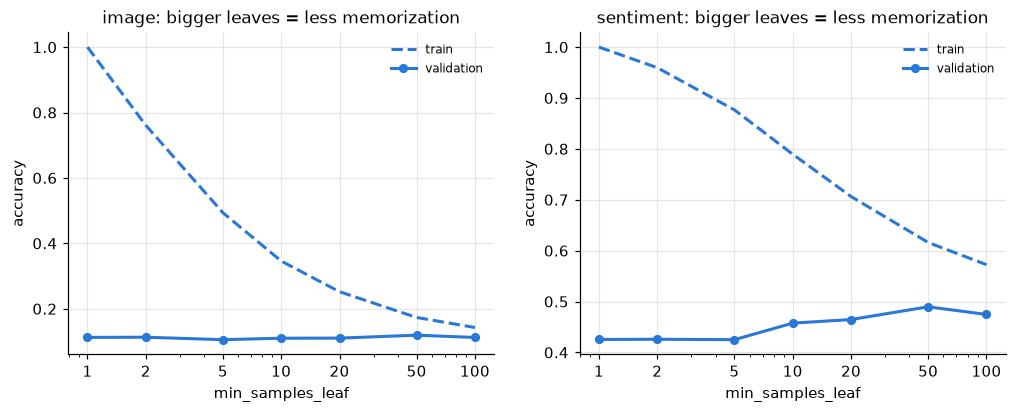

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, task in zip(axes, splits):
    r = min_results[(min_results.task == task) & (min_results.param == "min_samples_leaf")]
    ax.plot(r.value, r.train_acc, color=COLORS[0], linestyle="--", label="train")
    ax.plot(r.value, r.val_acc, color=COLORS[0], marker="o", label="validation")
    ax.set_xscale("log")
    ax.set_xticks(r.value)
    ax.set_xticklabels(r.value)
    ax.set_xlabel("min_samples_leaf")
    ax.set_ylabel("accuracy")
    ax.set_title(f"{task}: bigger leaves = less memorization")
    ax.legend(fontsize=8)
save_figure(fig, "03_dt_min_samples_leaf")
plt.show()

For **sentiment**, requiring bigger leaves raises validation accuracy from 42.5% (leaves of 1) to
49.0% (leaves of 50) while training accuracy falls from 100% to 62%: less overfitting, better
generalization. `min_samples_split` has a similar but weaker effect. For **images** validation
stays between 10.6% and 11.9% whatever we do: a single tree is the wrong tool for these features.

## 3. Depth and leaf size together

In [7]:
rows = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    for leaf in (1, 5, 20, 50):
        tree = DecisionTreeClassifier(criterion="gini", min_samples_leaf=leaf).fit(Xtr, ytr, N_CLASSES[task])
        for d in (4, 6, 8, 10, 12, 15, 20, None):
            rows.append(dict(task=task, min_samples_leaf=leaf, max_depth="none" if d is None else d,
                             val_acc=accuracy(yva, tree.predict(Xva, max_depth=d))))
grid = pd.DataFrame(rows)
for task in splits:
    print(task)
    print(grid[grid.task == task].pivot(index="max_depth", columns="min_samples_leaf", values="val_acc").round(3), "\n")

image
min_samples_leaf     1      5      20     50
max_depth                                   
4                 0.060  0.060  0.058  0.059
6                 0.063  0.062  0.061  0.064
8                 0.071  0.072  0.074  0.076
10                0.080  0.080  0.085  0.086
12                0.085  0.088  0.091  0.094
15                0.099  0.100  0.102  0.104
20                0.104  0.108  0.107  0.112
none              0.112  0.106  0.110  0.119 

sentiment
min_samples_leaf     1      5      20     50
max_depth                                   
4                 0.475  0.475  0.475  0.475
6                 0.480  0.480  0.479  0.483
8                 0.483  0.481  0.480  0.482
10                0.458  0.455  0.462  0.490
12                0.446  0.445  0.465  0.490
15                0.430  0.428  0.465  0.490
20                0.427  0.425  0.465  0.490
none              0.425  0.425  0.465  0.490 



For both tasks the best tree is **Gini, no depth limit, min_samples_leaf = 50**
(image 11.9%, sentiment 49.0%). Limiting the leaf size works better than limiting the depth.

## 4. Number of candidate thresholds (`n_bins`)

In [8]:
BEST = dict(criterion="gini", max_depth=None, min_samples_leaf=50)
rows = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    for n_bins in (8, 16, 32, 64, 128):
        with Timer() as t:
            tree = DecisionTreeClassifier(n_bins=n_bins, **BEST).fit(Xtr, ytr, N_CLASSES[task])
        rows.append(dict(task=task, n_bins=n_bins, train_acc=accuracy(ytr, tree.predict(Xtr)),
                         val_acc=accuracy(yva, tree.predict(Xva)), fit_s=round(t.seconds, 1)))
pd.DataFrame(rows).round(3)

,task,n_bins,train_acc,val_acc,fit_s
0,image,8,0.169,0.106,3.1
1,image,16,0.172,0.114,4.3
2,image,32,0.173,0.119,6.2
3,image,64,0.184,0.118,10.1
4,image,128,0.189,0.117,17.6
5,sentiment,8,0.606,0.477,1.4
6,sentiment,16,0.608,0.466,1.6
7,sentiment,32,0.616,0.490,1.9
8,sentiment,64,0.618,0.489,2.4
9,sentiment,128,0.623,0.478,3.2


32 bins is as good as 64 or 128 and faster to train, so we keep the default of 32.

## Final Decision Tree per task: save validation predictions (used in notebooks 04, 07 and 08)

In [9]:
summary = []
for task, (Xtr, ytr, Xva, yva) in splits.items():
    with Timer() as t_fit:
        tree = DecisionTreeClassifier(**BEST).fit(Xtr, ytr, N_CLASSES[task])
    with Timer() as t_pred:
        proba = tree.predict_proba(Xva)
    pred = proba.argmax(1)
    info = dict(model="Decision Tree", config=BEST, val_acc=accuracy(yva, pred),
                train_acc=accuracy(ytr, tree.predict(Xtr)), depth=tree.depth, leaves=tree.n_leaves,
                fit_seconds=t_fit.seconds, predict_seconds=t_pred.seconds)
    save_predictions(task, "dt", pred, proba, info)
    top = np.argsort(tree.feature_importances)[::-1][:5]
    summary.append(dict(task=task, depth=tree.depth, leaves=tree.n_leaves,
                        train_acc=round(info["train_acc"], 4), val_acc=round(info["val_acc"], 4),
                        most_used_features=", ".join(f"f{j}" for j in top)))
pd.DataFrame(summary)

,task,depth,leaves,train_acc,val_acc,most_used_features
0,image,42,236,0.1733,0.1192,"f230, f91, f405, f69, f454"
1,sentiment,13,144,0.6160,0.4896,"f42, f594, f2, f461, f1"
